# 06 · U6 실험 로그 분석 — 실행·추종·결과를 로그로 다시 확인하기

`evidence/{R,LOW,HIGH}`에는 Isaac Sim에서 실제로 돌린 세 조건의 원본 로그가 들어 있다. 이 노트북은 시뮬레이터를 다시 돌리지 않고 **로그만으로** README·노션에 적어 둔 수치를 다시 계산하고, U6 체크리스트에 답한다.

**학습 목표**

1. 로그 파일마다 무엇이 들어 있는지, `hand_experiment.py`의 어느 줄에서 쓰이는지 연결한다.
2. comparison.csv의 최소 이격·도달 시간·도달 오차를 `metrics.jsonl`에서 직접 재계산한다.
3. 이격 시계열, EE 경로, 손 정면 통과 높이로 세 조건의 행동 차이를 본다.
4. 상태 입력(measured), 상태 필터, PD 추종 오차, dt 설정을 로그로 확인한다.
5. feasible·실패 이벤트·관절 속도로 제약 위반 여부를 점검하고, 결과 해석의 한계를 정리한다.

### 노션 정리와의 연결 (U6)

| 노션 기록 | 이 노트북에서 확인하는 것 |
|---|---|
| U6 체크리스트: `input_actual_q_max_rad`로 MPC 입력과 실제 상태 차이 확인 | 최종 evidence는 `state_input=measured`라서 이 값은 구조적으로 0이다. 실제로 볼 값은 필터 출력·명령과 실제 상태의 차이 |
| U3/U5: MPC dt 0.02 s, physics dt ≈ 0.0167 s, horizon ≈ 0.75 s | 최종 실행은 `--model-dt 1/60`이라 model base dt = physics dt, horizon 합 = 0.675 s |
| U1: "직전 MPC 명령을 다음 MPC 상태로 사용" | 초기 설정(`--state-input command`) 기록. 최종 evidence는 측정 상태 사용 |
| 11.2절: R/LOW/HIGH(p=1) 최소 이격 −29.5 / −11.2 / +40.4 mm, A→B 2.83 / 3.08 / 3.17 s | 로그에서 재계산해 대조 |
| 11.2절: 손 정면 통과 EE 높이 LOW 0.505 / HIGH p=0.5 0.536 / HIGH p=1 0.627 m | 이 레포에는 R/LOW/HIGH(p=1)만 있으므로 그 셋만 확인. HIGH p=0.5는 확인 불가 |
| 11.3절: 전체 관측 전경 −13.9 → +40.3 mm | 사후 전체 점 재분석 결과라 evidence 로그에는 없다. 이 노트북 범위 밖 |

In [1]:
from common import *
plt = setup_plot()
import csv

FILES = ['metrics.jsonl', 'arrival-events.jsonl', 'goal-events.jsonl', 'summary.json',
         'control-settings.json', 'failure-events.json', 'mass-policy.json',
         'cost-connection.json', 'eta-after-run.json', 'patches-per-frame.jsonl']

def load(c):
    d = {}
    for f in FILES:
        p = EVIDENCE / c / f
        if not p.exists():
            continue
        d[f.split('.')[0]] = read_jsonl(p) if f.endswith('.jsonl') else json.loads(p.read_text())
    return d

E = {c: load(c) for c in CONDITIONS}
for c in CONDITIONS:
    print(c, {k: (len(v) if isinstance(v, list) else 'dict') for k, v in E[c].items()})

R {'metrics': 472, 'arrival-events': 2, 'goal-events': 2, 'summary': 'dict', 'control-settings': 'dict', 'failure-events': 0, 'mass-policy': 'dict', 'cost-connection': 'dict', 'patches-per-frame': 236}
LOW {'metrics': 472, 'arrival-events': 2, 'goal-events': 2, 'summary': 'dict', 'control-settings': 'dict', 'failure-events': 0, 'mass-policy': 'dict', 'cost-connection': 'dict', 'patches-per-frame': 236}
HIGH {'metrics': 472, 'arrival-events': 2, 'goal-events': 2, 'summary': 'dict', 'control-settings': 'dict', 'failure-events': 0, 'mass-policy': 'dict', 'cost-connection': 'dict', 'eta-after-run': 1, 'patches-per-frame': 236}


In [2]:
def col(c, key, missing=np.nan):
    """metrics.jsonl의 한 열을 numpy 배열로. None은 NaN."""
    return np.array([missing if r[key] is None else r[key] for r in E[c]['metrics']], dtype=float)

row = E['HIGH']['metrics'][200]
print('metrics 한 줄의 키 수:', len(row))
for k in ['step', 'sim_s', 'goal_index', 'position_error_m', 'original_surface_clearance_m',
          'target_cost_current', 'nearest_observed_surface_link', 'feasible', 'state_input',
          'input_actual_q_max_rad', 'filtered_actual_q_max_rad', 'command_actual_q_max_rad', 'solver_wall_s']:
    print(f'  {k:32s} {row[k]}')

metrics 한 줄의 키 수: 60
  step                             201
  sim_s                            3.350000174716115
  goal_index                       1
  position_error_m                 0.11007718741893768
  original_surface_clearance_m     0.33072733879089355
  target_cost_current              0.0
  nearest_observed_surface_link    panda_link7
  feasible                         [[True]]
  state_input                      measured
  input_actual_q_max_rad           0.0
  filtered_actual_q_max_rad        0.026827186346054077
  command_actual_q_max_rad         0.0302523672580719
  solver_wall_s                    0.010522411903366446


### 로그 파일과 코드 위치

| 파일 | 내용 | 쓰는 곳 (`experiment/`) |
|---|---|---|
| `metrics.jsonl` | 매 physics step 한 줄(472줄). 실제/명령/필터 관절, EE 오차, 이격, 비용 진단 | `hand_experiment.py:332-336` |
| `arrival-events.jsonl` | 실제 EE가 10 mm·0.05 rad 이내에 처음 들어온 시점 | `goal_progress.py:26` (`reach`) |
| `goal-events.jsonl` | 목표 지령 시점(A=0, B=1) | `hand_experiment.py:241` |
| `summary.json` | 도달 순서, 목표 구간(`goal_intervals`), 거리 정의 문자열 | `hand_experiment.py:356-357` |
| `control-settings.json` | 상태 입력, PD 게인, dt, 필터 계수 | `hand_experiment.py:346` |
| `failure-events.json` | infeasible 후 hold/recover 이벤트 | `hand_experiment.py:303-314, 347` |
| `mass-policy.json`, `cost-connection.json`, `eta-after-run.json` | 질량→η 정책, 비용 연결 정보, capture 후 실제 η 값 | `target_cost.py`, `hand_experiment.py:104-111, 350` |
| `patches-per-frame.jsonl` | 깊이 프레임마다 손 ROI 앵커 좌표 | `hand_experiment.py:270` |

이 실행의 한 스텝 순서는 `world.step`(228) → 깊이 프레임이 있으면 지도·ROI 갱신(243-246) → 측정 상태 읽기(278-286) → EE 오차·도달 판정(287-296) → `mpc.step`(298) → 명령 적용(317) → 이격·비용 진단 기록(320-336)이다.

## 1. 실행 설정 확인 — dt, horizon, 상태 입력, PD 게인

노션 U3에는 "MPC 적분 dt 0.02 s, physics dt ≈ 0.0167 s, 시간 비율 약 1.2"라는 의문이 남아 있었다. 최종 재생 명령(`scripts/replay.sh`)은 `--model-dt 0.016666666666666666`을 넘기므로 `MpcSolverConfig(step_dt=1/60)`(`hand_experiment.py:100`)가 되고, physics dt와 model base dt가 같아진다. horizon 30 step의 비균일 dt 합은 0.75 s가 아니라 0.675 s다.

In [3]:
cs = {c: E[c]['control-settings'] for c in CONDITIONS}
keys = ['state_input', 'drive_velocity_target', 'physics_dt', 'model_base_dt', 'trajectory_duration_s',
        'filter_enabled', 'filter_coeff', 'filter_dt', 'control_space', 'command_index', 'shift_steps']
for k in keys:
    vals = [cs[c][k] for c in CONDITIONS]
    same = all(v == vals[0] for v in vals)
    print(f'{k:24s} {vals[0]}' + ('' if same else f'   (조건별 다름: {vals})'))
kp, kd = cs['HIGH']['drive_stiffness'][0], cs['HIGH']['drive_damping'][0]
print(f'\nPD 게인 (7관절 동일): kp={kp:.1f}, kd={kd:.2f}, kd/kp={kd/kp:.4f} s')
print('세 조건 trajectory_dt 동일:', all(cs[c]['trajectory_dt'] == cs['R']['trajectory_dt'] for c in CONDITIONS))

state_input              measured
drive_velocity_target    zero
physics_dt               0.016666666666666666
model_base_dt            0.016666666666666666
trajectory_duration_s    0.675000011920929
filter_enabled           True
filter_coeff             {'position': 0.1, 'velocity': 0.1, 'acceleration': 0.0, 'jerk': 0.0}
filter_dt                0.016666666666666666
control_space            StateType.ACCELERATION
command_index            0
shift_steps              1

PD 게인 (7관절 동일): kp=35809.9, kd=572.96, kd/kp=0.0160 s
세 조건 trajectory_dt 동일: True


로그의 trajectory_dt 합   : 0.6750 s
dt_array(1/60) 합        : 0.6750 s  (로그와 최대 차 2.0e-09)
dt_array(0.02) 합 (노션) : 0.7500 s


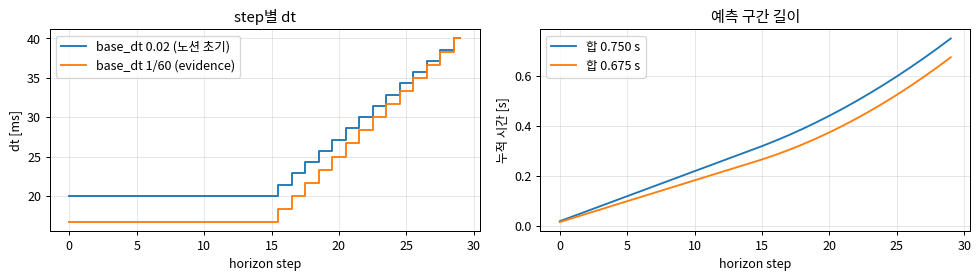

In [4]:
traj_dt = np.array(cs['HIGH']['trajectory_dt'])
old = dt_array(0.02)          # 노션 U3에서 계산한 초기 설정
new = dt_array(1 / 60)        # 최종 evidence 설정
print('로그의 trajectory_dt 합   : %.4f s' % traj_dt.sum())
print('dt_array(1/60) 합        : %.4f s  (로그와 최대 차 %.1e)' % (new.sum(), np.abs(new - traj_dt).max()))
print('dt_array(0.02) 합 (노션) : %.4f s' % old.sum())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].step(range(30), old * 1000, where='mid', label='base_dt 0.02 (노션 초기)')
ax[0].step(range(30), traj_dt * 1000, where='mid', label='base_dt 1/60 (evidence)')
ax[0].set(xlabel='horizon step', ylabel='dt [ms]', title='step별 dt')
ax[1].plot(np.cumsum(old), label='합 %.3f s' % old.sum())
ax[1].plot(np.cumsum(traj_dt), label='합 %.3f s' % traj_dt.sum())
ax[1].set(xlabel='horizon step', ylabel='누적 시간 [s]', title='예측 구간 길이')
for a in ax: a.legend()
plt.tight_layout()

**정리**

- `state_input = measured`: 매 스텝 Isaac Sim의 실제 관절 위치·속도를 MPC 입력으로 쓴다(`hand_experiment.py:278-285`). 노션 U1의 "직전 MPC 명령을 다음 입력으로 사용"은 `--state-input command`(기본값)였던 초기 실행의 기록이다.
- 측정 상태는 cuRobo 상태 필터(`filter_coeff` 위치·속도 0.1)를 거친 뒤 optimizer 시작 상태가 된다. `JointState.blend`(`curobo/types/state.py:170`)는 `새 값 = 0.1·측정 + 0.9·필터 내부 값`이다. 그래서 raw 측정과 optimizer 시작 상태는 같지 않다(3절에서 크기 확인).
- 명령은 위치 목표만 보낸다(`drive_velocity_target = zero`). PD 게인은 kp ≈ 35810, kd ≈ 573이다.
- `control_space = ACCELERATION`, `command_index 0`, `shift_steps 1`: 가속도열을 최적화하고 첫 스텝 명령만 실행한 뒤 1 스텝 shift해 warm start한다(노션 U1 구조와 같다).

### 질량 정책과 실제 η — 기록 시점에 주의

`cost-connection.json`은 `TargetCostChannel` 생성 직후(`hand_experiment.py:103`) 쓰이고, `--eta-exponent 1.0` 덮어쓰기는 그 다음 줄들(104-111)에서 일어난다. 그래서 HIGH의 `cost-connection.json`에는 p=0.5 값(42.87 mm)이 남아 있다. 실제로 쓰인 값은 덮어쓴 뒤 다시 저장한 `mass-policy.json`과, CUDA graph capture 이후 읽은 `eta-after-run.json`으로 확인해야 한다. 공개 evidence에는 `eta-after-run.json`이 HIGH 폴더에만 들어 있다.

In [5]:
print(f'{"조건":5s} {"정책키":7s} {"m_h":>5s} {"cost-connection η":>18s} {"mass-policy η":>14s} {"capture 후 η":>13s} {"alpha":>6s}')
for c in CONDITIONS:
    mp, cc = E[c]['mass-policy'], E[c]['cost-connection']
    after = f'{E[c]["eta-after-run"][0]["activation_m"]*1000:10.2f} mm' if 'eta-after-run' in E[c] else f'{"(파일 없음)":>13s}'
    print(f'{c:5s} {mp["condition"]:7s} {str(mp["assumed_hand_effective_mass_kg"]):>5s} '
          f'{cc["optimizers"][0]["activation_m"][0]*1000:15.2f} mm {mp["eta_calculated_m"]*1000:11.2f} mm '
          f'{after} {cc["alpha"]:6.1f}')
print('\ncommon.eta_policy 확인: LOW p=1 %.2f mm, HIGH p=0.5 %.2f mm, HIGH p=1 %.2f mm'
      % (eta_policy(0.6, 1) * 1000, eta_policy(2.3, 0.5) * 1000, eta_policy(2.3, 1) * 1000))
print('R의 alpha=0: 손 비용 객체는 만들어지지만 cost_fn에 연결되지 않는다 (base_target_cost.py:359).')

조건    정책키       m_h  cost-connection η  mass-policy η   capture 후 η  alpha
R     R        None           25.00 mm       25.00 mm       (파일 없음)    0.0
LOW   ETA06     0.6           25.00 mm       25.00 mm       (파일 없음)    1.0
HIGH  ETA23     2.3           42.87 mm       73.52 mm      73.52 mm    1.0

common.eta_policy 확인: LOW p=1 25.00 mm, HIGH p=0.5 42.87 mm, HIGH p=1 73.52 mm
R의 alpha=0: 손 비용 객체는 만들어지지만 cost_fn에 연결되지 않는다 (base_target_cost.py:359).


## 2. 도달 판정과 A→B 시간

목표 전환 규칙은 "실제 EE 위치 오차 ≤ 10 mm **그리고** 자세 오차 ≤ 0.05 rad를 처음 만족한 다음 스텝에 반대 목표 지령"이다(`hand_experiment.py:289-296`, `goal_progress.py:26-30`). `--goal-plan AB`라 B 도달 뒤에는 B를 유지한다. 시간은 모두 시뮬레이션 시간이고, A→B 시간은 **B 지령 시작 → 실제 B 도달**이다.

In [6]:
print(f'{"조건":5s} {"A 도달":>8s} {"B 지령":>8s} {"B 도달":>8s} {"A→B":>7s} {"B 위치오차":>10s} {"B 자세오차":>10s} {"도달 순서":>8s}')
arr = {}
for c in CONDITIONS:
    ev = {e['goal_index']: e for e in E[c]['arrival-events']}
    a, b = ev[0], ev[1]
    arr[c] = b
    print(f'{c:5s} {a["arrival_sim_s"]:7.3f}s {b["command_sim_s"]:7.3f}s {b["arrival_sim_s"]:7.3f}s '
          f'{b["duration_s"]:6.3f}s {b["arrival_position_error_m"]*1000:8.2f}mm {b["arrival_orientation_error_rad"]:8.4f}rad '
          f'{str(E[c]["summary"]["arrival_sequence"]):>8s}')
print('\n세 조건 모두 A 도달 step:', {c: E[c]['arrival-events'][0]['arrival_step'] for c in CONDITIONS})
print('B 지령 step:', {c: E[c]['goal-events'][1]['step'] for c in CONDITIONS})

조건        A 도달     B 지령     B 도달     A→B     B 위치오차     B 자세오차    도달 순서
R       2.167s   2.183s   5.017s  2.833s     2.44mm   0.0475rad   [0, 1]
LOW     2.167s   2.183s   5.267s  3.083s     9.77mm   0.0321rad   [0, 1]
HIGH    2.167s   2.183s   5.350s  3.167s     9.89mm   0.0282rad   [0, 1]

세 조건 모두 A 도달 step: {'R': 130, 'LOW': 130, 'HIGH': 130}
B 지령 step: {'R': 131, 'LOW': 131, 'HIGH': 131}


- A 도달(2.167 s, step 130)은 세 조건이 같다. 시작 자세에서 A로 가는 구간은 손 ROI와 멀어 손 비용이 0이고, seed·입력·설정이 같으므로 궤적이 같게 나온다.
- 차이는 B로 가는 구간에서만 생긴다: R 2.833 s < LOW 3.083 s < HIGH 3.167 s.
- 노션 11.2절의 HIGH p=0.5(3.53 s)가 HIGH p=1(3.17 s)보다 오래 걸린 것처럼, η가 크다고 항상 더 오래 걸리지는 않는다. 어떤 우회 경로를 고르느냐가 시간을 결정한다(p=0.5 로그는 이 레포에 없다).

## 3. 최소 이격 재계산과 comparison.csv 대조

`original_surface_clearance_m`(`target_margin.py:51-54`)의 정의:

$$
\text{clearance} = \min_{i,j}\left(\lVert p_j - c_i\rVert - r_i^{\text{buffered}}\right)
$$

- $p_j$: 그 시점 ROI 안 관측점(약 2,000점으로 솎음), $c_i, r_i$: 로봇 충돌 구 61개의 중심과 **20 mm buffer 포함** 반지름.
- 모든 구에 같은 buffer가 더해졌으므로 buffer를 뺀 값(bare)은 정확히 +20 mm다.
- 비교 구간은 `scripts/build_figures.py`와 같게 B 지령 step ~ B 도달 step이다.

In [7]:
with open(REPO / 'docs' / 'data' / 'comparison.csv') as f:
    ref = {r['condition']: r for r in csv.DictReader(f)}

mine = {}
for c in CONDITIONS:
    b = arr[c]
    step = col(c, 'step')
    sel = (step >= b['command_step']) & (step <= b['arrival_step'])
    gap = col(c, 'original_surface_clearance_m')[sel] * 1000
    bare = gap + 20
    i = int(np.nanargmin(gap))
    rows = [r for r, s in zip(E[c]['metrics'], sel) if s]
    mine[c] = dict(min_bare_sphere_clearance_mm=np.nanmin(bare), min_buffered_sphere_clearance_mm=np.nanmin(gap),
                   bare_negative_samples=int((bare < 0).sum()), buffered_negative_samples=int((gap < 0).sum()),
                   valid_samples=int(np.isfinite(gap).sum()), min_step=rows[i]['step'],
                   min_link=rows[i]['nearest_observed_surface_link'],
                   A_arrival_s=E[c]['arrival-events'][0]['arrival_sim_s'], B_command_s=b['command_sim_s'],
                   B_arrival_s=b['arrival_sim_s'], AB_duration_s=b['duration_s'],
                   B_position_error_mm=rows[-1]['position_error_m'] * 1000,
                   B_orientation_error_rad=rows[-1]['orientation_error_rad'])

print(f'{"항목":32s}' + ''.join(f'{c:>22s}' for c in CONDITIONS))
for k in mine['R']:
    line = f'{k:32s}'
    for c in CONDITIONS:
        v, r = mine[c][k], ref[c][k]
        if isinstance(v, str):
            ok = v == r
            line += f'{v:>18s} {"✓" if ok else "✗":>3s}'
        else:
            ok = abs(float(v) - float(r)) < 1e-6
            line += f'{float(v):18.4f} {"✓" if ok else "✗":>3s}'
    print(line)

항목                                                   R                   LOW                  HIGH
min_bare_sphere_clearance_mm               -9.5400   ✓            8.8045   ✓           60.4343   ✓
min_buffered_sphere_clearance_mm          -29.5400   ✓          -11.1955   ✓           40.4343   ✓
bare_negative_samples                       7.0000   ✓            0.0000   ✓            0.0000   ✓
buffered_negative_samples                   7.0000   ✓           11.0000   ✓            0.0000   ✓
valid_samples                             171.0000   ✓          186.0000   ✓          191.0000   ✓
min_step                                  163.0000   ✓          169.0000   ✓          165.0000   ✓
min_link                               panda_link5   ✓       panda_link7   ✓        panda_hand   ✓
A_arrival_s                                 2.1667   ✓            2.1667   ✓            2.1667   ✓
B_command_s                                 2.1833   ✓            2.1833   ✓            2.1833   ✓
B_arrival_

로그에서 다시 계산한 값이 comparison.csv와 모두 일치하면(✓) README 표의 출처가 `metrics.jsonl`과 `arrival-events.jsonl`이라는 것이 확인된다.

| 조건 | bare 최소 | buffered 최소 | 시점 / 링크 | 노션 11.2 (buffered) |
|---|---:|---:|---|---:|
| R | −9.54 mm | −29.54 mm | step 163 / panda_link5 | −29.5 mm |
| LOW | +8.80 mm | −11.20 mm | step 169 / panda_link7 | −11.2 mm |
| HIGH p=1 | +60.43 mm | +40.43 mm | step 165 / panda_hand | +40.4 mm |

노션 11.3절의 "전체 관측 전경" 값(−46.1 / −13.9 / +40.3 mm)은 ROI 밖 손끝·손목까지 전체 점으로 다시 계산한 사후 분석이라 이 로그로는 재현할 수 없다. 거리 기준이 다르다는 점(ROI 솎은 점 vs 전경 전체 점)을 섞지 않는다.

## 4. 시계열 — 이격, 목표 오차, 손 비용, solver 시간

`target_cost_current`(`hand_experiment.py:114-117, 325`)는 **현재 실제 자세 한 시점**에 대한 손 비용 진단값이다(weight 100000 포함, horizon 합 아님).
- LOW/HIGH: optimizer에 연결된 것과 같은 η로 계산한 값.
- R: optimizer에는 연결되지 않았지만(alpha=0) 진단 객체는 η=25 mm로 만들어져 있다. 즉 R 그래프의 손 비용은 "LOW였다면 받았을 비용"이고 R의 행동에는 영향이 없다.

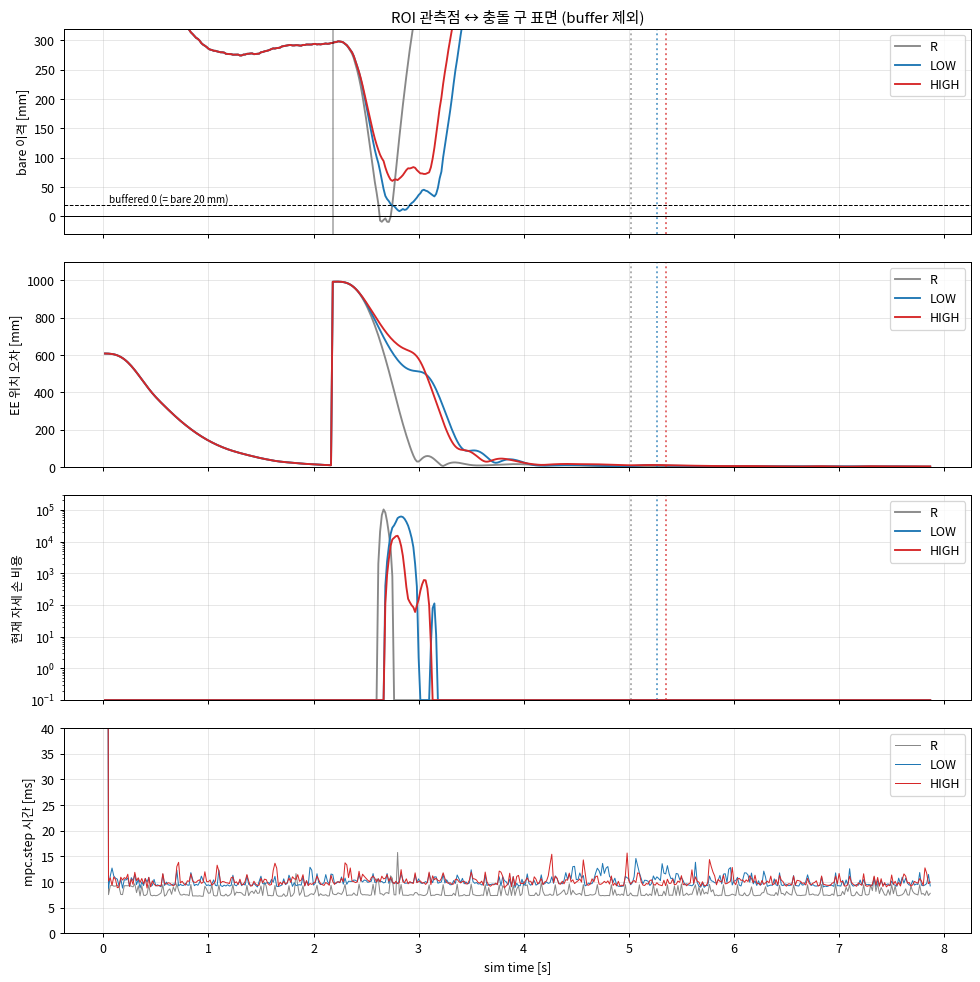

In [8]:
fig, ax = plt.subplots(4, 1, figsize=(11, 11), sharex=True)
for c in CONDITIONS:
    t = col(c, 'sim_s')
    ax[0].plot(t, col(c, 'original_surface_clearance_m') * 1000 + 20, color=COLORS[c], label=c)
    ax[1].plot(t, col(c, 'position_error_m') * 1000, color=COLORS[c], label=c)
    ax[2].semilogy(t, np.maximum(col(c, 'target_cost_current'), 1e-1), color=COLORS[c], label=c)
    ax[3].plot(t, col(c, 'solver_wall_s') * 1000, color=COLORS[c], label=c, lw=0.8)
    for a in ax[:3]:
        a.axvline(arr[c]['arrival_sim_s'], color=COLORS[c], ls=':', alpha=0.7)
ax[0].axhline(0, color='k', lw=0.8)
ax[0].axhline(20, color='k', lw=0.8, ls='--')
ax[0].text(0.05, 23, 'buffered 0 (= bare 20 mm)', fontsize=8)
ax[0].set(ylabel='bare 이격 [mm]', title='ROI 관측점 ↔ 충돌 구 표면 (buffer 제외)', ylim=(-30, 320))
ax[1].set(ylabel='EE 위치 오차 [mm]', ylim=(0, 1100))
ax[2].set(ylabel='현재 자세 손 비용', ylim=(1e-1, 3e5))
ax[3].set(ylabel='mpc.step 시간 [ms]', xlabel='sim time [s]', ylim=(0, 40))
ax[0].axvline(E['R']['goal-events'][1]['sim_s'], color='k', alpha=0.3)
for a in ax: a.legend(loc='upper right')
plt.tight_layout()

In [9]:
for c in CONDITIONS:
    w = col(c, 'solver_wall_s')
    print(f'{c:5s} solver: 첫 step {w[0]*1000:6.1f} ms | 이후 평균 {w[1:].mean()*1000:5.2f} ms, '
          f'99% {np.percentile(w[1:], 99)*1000:5.2f} ms, 최대 {w[1:].max()*1000:5.2f} ms | physics dt {1000/60:.2f} ms')
    tc = col(c, 'target_cost_current')
    print(f'      손 비용>0 인 step 수 {int((tc > 0).sum())}, 최대 {tc.max():.0f} (step {int(col(c, "step")[tc.argmax()])})')

R     solver: 첫 step  799.0 ms | 이후 평균  8.35 ms, 99% 10.79 ms, 최대 194.11 ms | physics dt 16.67 ms
      손 비용>0 인 step 수 9, 최대 104124 (step 160)
LOW   solver: 첫 step  783.8 ms | 이후 평균 10.52 ms, 99% 13.30 ms, 최대 191.10 ms | physics dt 16.67 ms
      손 비용>0 인 step 수 24, 최대 62427 (step 170)
HIGH  solver: 첫 step  793.3 ms | 이후 평균 10.64 ms, 99% 13.96 ms, 최대 207.93 ms | physics dt 16.67 ms
      손 비용>0 인 step 수 27, 최대 15372 (step 168)


- 첫 `mpc.step`이 약 0.8 s인 것은 CUDA graph capture 비용이다. 이후 평균 8~11 ms, 99%가 14 ms 이하로 physics dt(16.7 ms)보다 짧지만, 드물게 약 0.2 s 튀는 스텝이 있다. 다만 이 실행은 sim이 solver를 기다리는 동기 루프라서, solver 시간이 실시간성을 깨더라도 결과 궤적에는 반영되지 않는다.
- 손 비용은 B 구간 앞부분(손 근처 통과)에서만 0이 아니다. HIGH는 η가 커서 더 먼 거리부터 비용이 생기지만, 실제로 멀리 피하기 때문에 현재 자세의 최대 비용은 LOW·R 진단값보다 작다.

## 5. EE 경로와 손 정면 통과 높이

손 ROI 앵커(`patches-per-frame.jsonl`)를 같이 그리면 경로가 손을 어떻게 돌아가는지 보인다. 손은 정적이라 HOLD 구간 앵커를 모두 겹쳐 그렸다.

앵커 점 수(전 프레임 합): 6284 | 프레임당 앵커 수 범위: 10 ~ 35


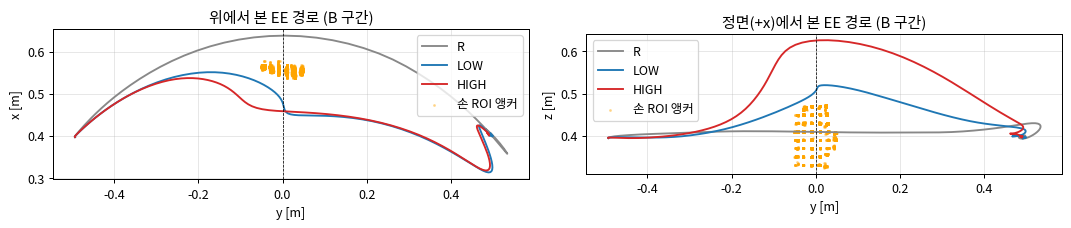

In [10]:
anch = np.array([a for p in E['HIGH']['patches-per-frame'] for a in p['anchors']])
print('앵커 점 수(전 프레임 합):', len(anch), '| 프레임당 앵커 수 범위:',
      min(p['count'] for p in E['HIGH']['patches-per-frame']), '~', max(p['count'] for p in E['HIGH']['patches-per-frame']))

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for c in CONDITIONS:
    ee = np.array([r['ee_position'] for r in E[c]['metrics']])
    sel = col(c, 'goal_index') == 1
    sel &= col(c, 'step') <= arr[c]['arrival_step']
    ax[0].plot(ee[sel, 1], ee[sel, 0], color=COLORS[c], label=c)
    ax[1].plot(ee[sel, 1], ee[sel, 2], color=COLORS[c], label=c)
ax[0].scatter(anch[:, 1], anch[:, 0], s=2, c='orange', alpha=0.3, label='손 ROI 앵커')
ax[1].scatter(anch[:, 1], anch[:, 2], s=2, c='orange', alpha=0.3, label='손 ROI 앵커')
ax[0].set(xlabel='y [m]', ylabel='x [m]', title='위에서 본 EE 경로 (B 구간)')
ax[1].set(xlabel='y [m]', ylabel='z [m]', title='정면(+x)에서 본 EE 경로 (B 구간)')
for a in ax:
    a.axvline(0, color='k', lw=0.6, ls='--')
    a.legend()
    a.set_aspect('equal')
plt.tight_layout()

In [11]:
notion = {'LOW': 0.505, 'HIGH': 0.627}
print('B 구간에서 EE가 y=0 을 지나는 순간 (선형 보간)')
for c in CONDITIONS:
    rows = E[c]['metrics']
    ee = np.array([r['ee_position'] for r in rows])
    g = col(c, 'goal_index')
    for j in range(1, len(rows)):
        if g[j] == 1 and ee[j - 1, 1] < 0 <= ee[j, 1]:
            a = -ee[j - 1, 1] / (ee[j, 1] - ee[j - 1, 1])
            p = ee[j - 1] + a * (ee[j] - ee[j - 1])
            ref_txt = f' | 노션 {notion[c]:.3f} m' if c in notion else ''
            print(f'  {c:5s} step {rows[j]["step"]}  x={p[0]:.3f} m  z={p[2]:.3f} m{ref_txt}')
print('  HIGH p=0.5 (노션 0.536 m)는 evidence에 로그가 없어 확인 불가')

B 구간에서 EE가 y=0 을 지나는 순간 (선형 보간)
  R     step 162  x=0.638 m  z=0.409 m
  LOW   step 177  x=0.480 m  z=0.506 m | 노션 0.505 m
  HIGH  step 182  x=0.459 m  z=0.626 m | 노션 0.627 m
  HIGH p=0.5 (노션 0.536 m)는 evidence에 로그가 없어 확인 불가


- 손 앵커는 x ≈ 0.55~0.58 m, z ≈ 0.32~0.47 m에 있다. R의 EE는 손보다 로봇에서 먼 쪽(x ≈ 0.64 m)으로 크게 돌면서 손 높이 범위 안(z ≈ 0.41 m)을 지나고, 이때 팔(panda_link5)이 손 관측면과 겹친다(3절의 step 163).
- LOW·HIGH는 x를 줄여 로봇 쪽으로 물러나고 손 위쪽으로 지나간다. HIGH가 가장 높다(z ≈ 0.63 m).
- 노션의 LOW 0.505 m, HIGH(p=1) 0.627 m와 소수 셋째 자리 수준에서 맞는다.

## 6. MPPI 후보 단위 통계 — 손 비용이 가중치에 미친 영향

`candidate_target_stats`(`static_gui.py:44-52`)는 매 스텝 마지막 MPPI 반복의 400개 후보 중

- `target_nonzero_candidates`: horizon 합 손 비용이 0보다 큰 후보 수
- `target_weight_mass`: 그 후보들이 가진 MPPI 가중치 합의 비율(0~1)
- `best_candidate_target`: 가중치 최대 후보의 손 비용

을 기록한다. R은 손 비용이 연결되지 않아 None이다.

LOW   손 비용 후보가 있는 step 56개 (sim 2.22~3.13s) | 그중 가중치가 손 비용 후보에 몰린 step(>0.5) 55개
HIGH  손 비용 후보가 있는 step 61개 (sim 2.20~3.65s) | 그중 가중치가 손 비용 후보에 몰린 step(>0.5) 54개


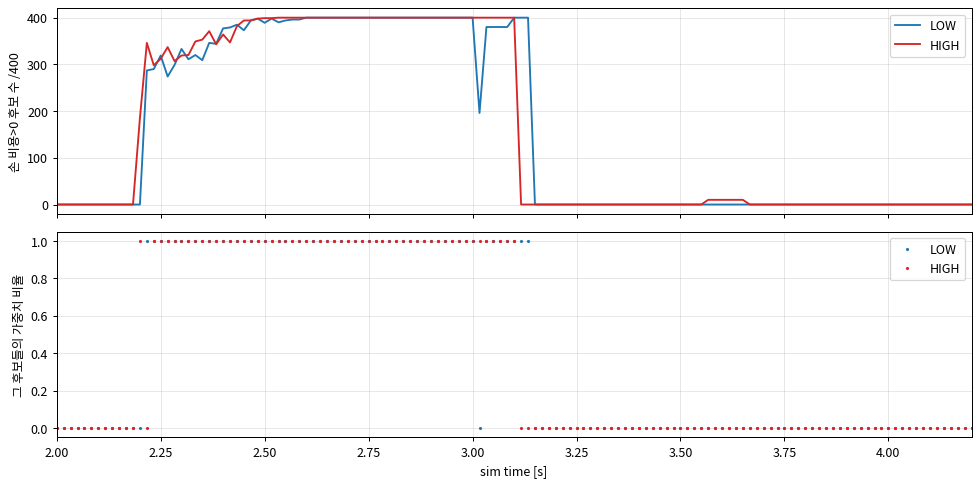

In [12]:
fig, ax = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
for c in ['LOW', 'HIGH']:
    t = col(c, 'sim_s')
    ax[0].plot(t, col(c, 'target_nonzero_candidates'), color=COLORS[c], label=c)
    ax[1].plot(t, col(c, 'target_weight_mass'), '.', ms=3, color=COLORS[c], label=c)
    nz = col(c, 'target_nonzero_candidates')
    wm = col(c, 'target_weight_mass')
    on = nz > 0
    print(f'{c:5s} 손 비용 후보가 있는 step {int(on.sum())}개 '
          f'(sim {t[on].min():.2f}~{t[on].max():.2f}s) | 그중 가중치가 손 비용 후보에 몰린 step(>0.5) {int((wm[on] > 0.5).sum())}개')
ax[0].set(ylabel='손 비용>0 후보 수 /400', xlim=(2, 4.2))
ax[1].set(ylabel='그 후보들의 가중치 비율', xlabel='sim time [s]')
for a in ax: a.legend()
plt.tight_layout()

가중치 비율이 1이면 "가장 좋은 후보들도 손 활성 거리 안으로 들어간다", 0이면 "손 비용이 0인 후보가 충분히 좋아서 가중치를 가져간다"는 뜻이다. LOW 56개 중 55개, HIGH 61개 중 54개 스텝에서 비율이 0.5를 넘었다. 즉 손 근처를 지나는 동안 실제로 선택된 계획은 대부분 손 비용을 받으면서 그 크기를 줄이는 방향이었다. 값이 중간보다 0 또는 1 근처에 몰리는 것은 β=0.1에서 가중치가 한두 후보에 몰리기 때문이다(노션 U2의 β 해석, 11.2절의 "특정 시점에는 후보 가중치가 하나에 집중").

## 7. 상태 입력과 추종 오차

세 가지 차이를 구분한다.

| 로그 키 | 의미 | 정의 위치 |
|---|---|---|
| `input_actual_q_max_rad` | MPC에 넘긴 상태 − 실제 관절 위치 | `hand_experiment.py:332` |
| `filtered_actual_q_max_rad` | cuRobo 필터 출력(optimizer 시작 상태) − 실제 | `hand_experiment.py:334` |
| `command_actual_q_max_rad` | 이번 스텝 위치 명령 − 실제 (PD가 따라가야 할 거리) | `hand_experiment.py:334` |

`state_input=measured`에서는 넘기는 상태가 곧 측정값이므로 첫 번째는 정의상 0이다(285줄 assert). 노션 U6 체크리스트의 질문은 `command` 모드를 전제로 한 것이었다.

                                                       R                 LOW                HIGH
input_actual_q_max_rad                평균 0.0000 최대 0.0000  평균 0.0000 최대 0.0000  평균 0.0000 최대 0.0000
filtered_actual_q_max_rad             평균 0.0063 최대 0.0223  평균 0.0074 최대 0.0364  평균 0.0071 최대 0.0337
command_actual_q_max_rad              평균 0.0151 최대 0.0499  평균 0.0153 최대 0.0465  평균 0.0161 최대 0.0472
filtered_actual_velocity_max_rad_s    평균 0.1939 최대 0.5594  평균 0.2030 최대 0.5594  평균 0.2097 최대 0.5594


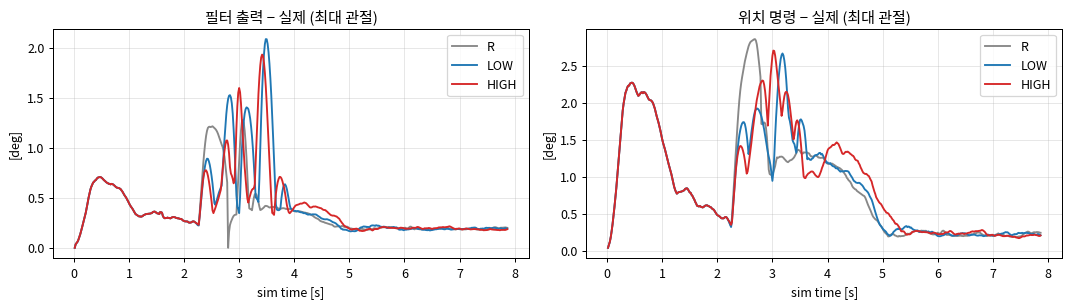

In [13]:
keys = ['input_actual_q_max_rad', 'filtered_actual_q_max_rad', 'command_actual_q_max_rad', 'filtered_actual_velocity_max_rad_s']
print(f'{"":36s}' + ''.join(f'{c:>20s}' for c in CONDITIONS))
for k in keys:
    print(f'{k:36s}' + ''.join(f'  평균 {col(c, k).mean():.4f} 최대 {col(c, k).max():.4f}' for c in CONDITIONS))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for c in CONDITIONS:
    t = col(c, 'sim_s')
    ax[0].plot(t, np.degrees(col(c, 'filtered_actual_q_max_rad')), color=COLORS[c], label=c)
    ax[1].plot(t, np.degrees(col(c, 'command_actual_q_max_rad')), color=COLORS[c], label=c)
ax[0].set(title='필터 출력 − 실제 (최대 관절)', ylabel='[deg]', xlabel='sim time [s]')
ax[1].set(title='위치 명령 − 실제 (최대 관절)', ylabel='[deg]', xlabel='sim time [s]')
for a in ax: a.legend()
plt.tight_layout()

- 필터 출력과 실제 위치의 차이는 최대 약 2° 수준이다. MPPI는 이 필터 상태에서 rollout을 시작하므로, "측정 상태를 넣었다"가 "optimizer가 정확히 현재 상태에서 계획했다"를 뜻하지는 않는다.
- 명령과 실제의 차이(최대 약 2.9°)는 위치 PD가 한 스텝 안에 따라가지 못한 양이다. 이동 중에 커지고 정지하면 0에 가까워진다.
- 이 차이들이 이격 결과를 얼마나 바꾸는지는 이 로그만으로는 분리할 수 없다(같은 조건에서 필터·드라이브만 바꾼 비교 실행이 필요).

## 8. 제약 위반 점검 — feasible, 실패 이벤트, 관절 속도

`feasible`은 cuRobo가 반환 명령에 대해 설정된 제약(관절 한계, 자체 충돌, 환경 충돌 등) 검사를 통과했는지다. **손 비용은 이 판정에 들어가지 않는다**(`cost-connection.json`의 `aux_and_safety_costs` 문구, `docs/diagnosis.md`). 실패하면 `--failure-action hold-measured`로 측정 위치를 유지하도록 되어 있다(`hand_experiment.py:311-314`).

In [14]:
import xml.etree.ElementTree as ET
urdf = CUROBO / 'src/curobo/content/assets/robot/franka_description/franka_panda.urdf'
lim = {}
for j in ET.parse(urdf).getroot().findall('joint'):
    l = j.find('limit')
    if j.get('name').startswith('panda_joint') and l is not None:
        lim[j.get('name')] = float(l.get('velocity'))
vlim = np.array([lim[f'panda_joint{i}'] for i in range(1, 8)])
print('URDF 속도 한계 [rad/s]:', vlim)
print(E['HIGH']['cost-connection']['aux_and_safety_costs'])
print()
for c in CONDITIONS:
    m = E[c]['metrics']
    feas = np.array([all(r['feasible']) for r in m])
    hold = sum(r['hold_applied'] for r in m)
    v = np.abs(np.array([r['actual_velocity'] for r in m]))
    vc = np.abs(np.array([r['command_velocity'] for r in m]))
    ratio = (v / vlim).max(0)
    print(f'{c:5s} feasible {feas.mean()*100:.1f}% | hold {hold} | failure-events {len(E[c]["failure-events"])} | '
          f'실제 속도/한계 최대 {ratio.max():.2f} (joint{ratio.argmax()+1}) | 명령 속도/한계 최대 {(vc/vlim).max():.2f} | '
          f'한계 초과 step {int((v > vlim).any(1).sum())} | 자체충돌 비용 최대 {col(c, "self_collision_cost_max").max():.1f}')

URDF 속도 한계 [rad/s]: [2.175 2.175 2.175 2.175 2.61  2.61  2.61 ]
unchanged; reported constraints do not include target penalty

R     feasible 100.0% | hold 0 | failure-events 0 | 실제 속도/한계 최대 0.85 (joint1) | 명령 속도/한계 최대 0.88 | 한계 초과 step 0 | 자체충돌 비용 최대 0.0
LOW   feasible 100.0% | hold 0 | failure-events 0 | 실제 속도/한계 최대 0.69 (joint1) | 명령 속도/한계 최대 0.75 | 한계 초과 step 0 | 자체충돌 비용 최대 0.0
HIGH  feasible 100.0% | hold 0 | failure-events 0 | 실제 속도/한계 최대 0.80 (joint1) | 명령 속도/한계 최대 0.75 | 한계 초과 step 0 | 자체충돌 비용 최대 0.0


- 세 조건 모두 472 스텝 전부 feasible, hold 0회, 실패 이벤트 없음.
- 실제 관절 속도는 URDF 한계의 최대 0.85배(R, joint1), 명령 속도는 최대 0.88배로 한계를 넘은 스텝이 없다(노션 11.2절의 "관절 속도 초과 0회"와 일치).
- R도 feasible이었다는 점이 중요하다. R은 손과 buffered 기준 −29.5 mm 겹쳤지만 feasible이었다. feasible은 손 관측면과의 비접촉을 보장하지 않는다.

## 9. U6 체크리스트 답변

| 노션 U6 항목 | 답 | 근거 |
|---|---|---|
| `input_actual_q_max_rad`로 MPC 입력과 실제 상태 차이 확인 | **확인됨, 단 의미가 바뀜.** measured 입력이라 0. 실제 차이는 필터 출력(최대 약 0.036 rad)과 명령(최대 약 0.05 rad)에서 생긴다 | 7절 |
| MPC 적분 dt와 명령 적용 주기·physics step 관계 | **확인됨.** model base dt = physics dt = 1/60 s, 한 physics step에 `mpc.step` 1회, horizon 0.675 s | 1절 |
| R / ETA06 / ETA23 최소 이격과 시간 추이 | **확인됨(R / LOW / HIGH p=1).** 초기 ETA23(p=0.5) 로그는 이 레포에 없음 | 3, 4절 |
| 목표 위치·자세 오차와 실제 도달 여부 | **확인됨.** 세 조건 모두 A, B 도달. B 도달 오차 2.44 / 9.77 / 9.89 mm | 2절 |
| 회피 시작·정지 시간·머뭇거림·왕복 완료 횟수 | **부분 확인.** A→B 시간과 경로 차이는 확인. 이 실험은 `goal-plan AB`라 왕복 완료는 정의상 0회. "회피 시작 시점"은 정의를 정하지 않아 판정하지 않음 | 2, 5, 6절 |
| 여러 seed 반복과 실패 사례 | **로그로 확인 불가.** seed 0 단일 실행. 실패 이벤트 없음 | 8절 |

## 10. 해석의 한계

- **단일 장면·단일 seed·조건별 1회 실행.** 차이의 크기에 대한 통계적 신뢰 구간은 없다.
- **거리 기준.** 관측된 ROI 점(약 2,000점으로 솎음) ↔ 61개 근사 충돌 구. 실제 Franka mesh, 손의 가려진 뒷면, ROI 밖 손끝·손목은 이 로그의 거리에 들어가지 않는다.
- **R→LOW 차이에는 두 효과가 섞여 있다.** 손 관측 패치 표현 도입(미관측 ESDF로 빠진 비용을 보완)과 추가 페널티. 질량 가정의 효과만 보려면 LOW→HIGH를 본다(`docs/diagnosis.md`).
- **η는 비용 활성화 거리.** HIGH에서 +40 mm(buffered)가 나왔다고 73.5 mm 이격이 보장되는 것은 아니다.
- **가상 로봇 + 기록 깊이.** 손은 정지해 있었고 Franka는 시뮬레이션에서만 움직였다. 실제 접촉력·실로봇 안전성 검증이 아니다.

## 정정 포인트

| 이전 이해 (노션 기록 시점) | 로그로 확인한 내용 |
|---|---|
| MPC 입력은 직전 MPC 명령 | 최종 evidence는 `state_input=measured`. 명령 입력은 초기 실험 설정 |
| MPC dt 0.02 s vs physics dt 0.0167 s, 비율 1.2 | 최종 실행은 `--model-dt 1/60`으로 둘이 같다 |
| horizon ≈ 0.75 s | base dt 1/60에서 0.675 s (`trajectory_duration_s`) |
| `input_actual_q_max_rad`로 입력-실제 차이 확인 | measured 모드에선 항상 0. 필터 출력·명령과의 차이를 봐야 한다 |
| HIGH의 η는 `cost-connection.json`에서 읽으면 된다 | 그 파일은 p=1 덮어쓰기 전에 쓰여 42.87 mm가 남아 있다. 실제 값은 `mass-policy.json`, `eta-after-run.json` (73.52 mm) |
| R의 `target_cost_current`가 0이 아니면 R에도 손 비용이 작용 | 진단용으로만 계산된 값(η 25 mm). R optimizer에는 연결되지 않았다 |
| feasible이면 손과 충돌하지 않았다 | 손 비용은 feasible 판정에 없다. R도 100% feasible |

## 복습 질문

<details><summary>1. comparison.csv의 R 최소 이격이 bare −9.54 mm, buffered −29.54 mm인데, 왜 정확히 20 mm 차이인가?</summary>

모든 충돌 구에 같은 20 mm buffer가 반지름에 더해졌고, 같은 점 집합·같은 구 집합에서 최솟값을 취하므로 최솟값도 정확히 20 mm 이동한다(`hand_experiment.py:90`의 `collision_sphere_buffer=.02`).
</details>

<details><summary>2. 세 조건의 A 도달 시각이 모두 2.167 s로 같은 이유는?</summary>

A로 가는 구간에서는 로봇이 손 ROI 활성 거리 밖에 있어 손 비용이 0이고, 입력·seed·fixed sampling·설정이 같으므로 MPPI 계산이 같다. 조건 차이는 손 근처를 지나는 B 구간에서만 나타난다.
</details>

<details><summary>3. measured 입력인데도 MPPI rollout 시작 상태와 실제 상태가 다른 이유는?</summary>

측정 상태가 cuRobo 상태 필터(`filter_coeff` 0.1)를 거쳐 optimizer 시작 상태가 되기 때문이다. 새 값 = 0.1·측정 + 0.9·필터 내부 값이라, 측정값이 바로 반영되지 않고 이전 값 쪽으로 끌린다.
</details>

<details><summary>4. HIGH의 `cost-connection.json`에 activation 42.87 mm가 적혀 있다. HIGH는 p=0.5로 실행된 것인가?</summary>

아니다. 이 파일은 `TargetCostChannel` 생성 시(103줄) 쓰이고, `--eta-exponent 1.0` 덮어쓰기는 104-111줄에서 capture 전에 일어난다. capture 이후 읽은 `eta-after-run.json`이 73.52 mm를 보여준다.
</details>

<details><summary>5. R의 그래프에 손 비용(target_cost_current)이 10만 이상으로 찍힌다. R이 손을 피하지 않은 것과 모순 아닌가?</summary>

R의 그 값은 진단용 객체(η 25 mm)로 계산만 한 것이고 optimizer cost_fn에는 연결되지 않았다(alpha=0, hook 없음). R의 optimizer가 본 손 관련 비용은 nvblox 환경 비용뿐이었고, 구 중심이 미관측 ESDF에 있어 0이었다(U4).
</details>

<details><summary>6. "HIGH는 최소 이격 +40 mm였으므로 η가 클수록 안전하다"는 결론의 문제점은?</summary>

단일 장면·seed 결과이고, 거리는 ROI 관측점과 buffered 구 기준이며, η는 비용 활성 거리일 뿐 보장 거리가 아니다. HIGH p=0.5와 p=1의 이동 시간이 η 순서와 다르게 나온 것처럼 경로 선택이 결과를 좌우한다.
</details>

---

**다음:** `07_isaacsim_mpc_lab.ipynb` — Isaac Sim에서 cuRobo MPC 루프를 직접 띄워 보고, 이 노트북에서 본 로그 항목들이 실행 루프의 어디서 나오는지 손으로 확인한다.